In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [101]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# TASK 1: Load & Explore the Dataset


In [102]:
df = pd.read_csv("/content/output.csv")

In [103]:
df.shape

(1000, 2)

In [104]:
df.columns

Index([' Review', 'Liked'], dtype='object')

In [105]:
# rename column - Review
df.rename(columns = {' Review':'Review'}, inplace = True)

In [106]:
df.columns

Index(['Review', 'Liked'], dtype='object')

In [107]:
df.head(10)

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1
5,Now I am getting angry and I want my damn pho.,0
6,Honeslty it didn't taste THAT fresh.),0
7,The potatoes were like rubber and you could te...,0
8,The fries were great too.,1
9,A great touch.,1


In [108]:
# check no of samples per class
df["Liked"].value_counts()

,count
Liked,
1,500
0,500


In [109]:
# check missing values
df.isnull().sum()

,0
Review,0
Liked,0


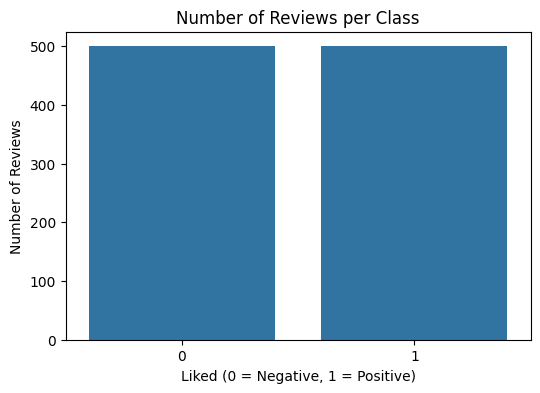

In [110]:
# Review text length distribution
df["Review_Length"] = df["Review"].apply(len)

# Class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Liked")
plt.title("Number of Reviews per Class")
plt.xlabel("Liked (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")
plt.show()

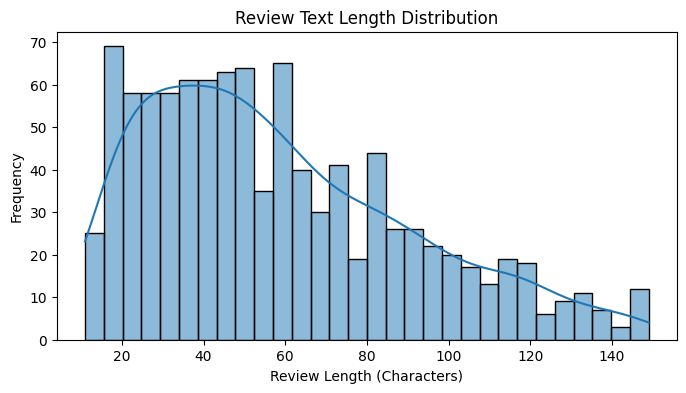

In [111]:
# Review length distribution
plt.figure(figsize=(8, 4))
sns.histplot(df["Review_Length"], bins=30, kde=True)
plt.title("Review Text Length Distribution")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Frequency")
plt.show()

In [112]:
print(df["Review_Length"].describe())

count    1000.000000
mean       58.315000
std        32.360052
min        11.000000
25%        33.000000
50%        51.000000
75%        80.000000
max       149.000000
Name: Review_Length, dtype: float64


# TASK 2: Clean & Preprocess the Text


In [113]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

stop_words = set(stopwords.words("english"))

important_words = {
    "no", "not", "nor", "neither", "never",
    "nothing", "nowhere", "hardly", "barely", "scarcely",
    "but", "however", "although", "though", "yet", "while",
    "very", "too", "so", "really", "quite",
    "extremely", "highly", "completely", "absolutely"
}

stop_words -= important_words

lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [114]:
import re

# Expand common contractions
contractions = {
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "can't": "cannot",
    "couldn't": "could not",
    "wouldn't": "would not",
    "shouldn't": "should not",
    "won't": "will not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "haven't": "have not",
    "hasn't": "has not",
    "hadn't": "had not",
    "mustn't": "must not",
    "needn't": "need not",
    "i'm": "i am",
    "you're": "you are",
    "we're": "we are",
    "they're": "they are",
    "it's": "it is",
    "that's": "that is",
    "there's": "there is",
    "i've": "i have",
    "you've": "you have",
    "we've": "we have",
    "they've": "they have",
    "i'll": "i will",
    "you'll": "you will",
    "we'll": "we will",
    "they'll": "they will",
    "i'd": "i would",
    "you'd": "you would",
    "we'd": "we would",
    "they'd": "they would",
    "what's": "what is",
    "who's": "who is",
    "let's": "let us"
}


def clean_text(text):
    # 1. Convert to lowercase
    text = str(text).lower()

    # 2. Expand contractions BEFORE removing punctuation
    for contraction, expansion in contractions.items():
        text = re.sub(
            r"\b" + re.escape(contraction) + r"\b",
            expansion,
            text
        )

    # 3. Remove numbers
    text = re.sub(r"\d+", "", text)

    # 4. Remove punctuation and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # 5. Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # 6. Tokenize, remove stopwords and lemmatize
    words = text.split()

    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)


# Apply cleaning to all reviews
df["cleaned_review"] = df["Review"].apply(clean_text)

# Compare original and cleaned reviews
print(df[["Review", "cleaned_review"]].head(10))

                                              Review  \
0                           Wow... Loved this place.   
1                                 Crust is not good.   
2          Not tasty and the texture was just nasty.   
3  Stopped by during the late May bank holiday of...   
4  The selection on the menu was great and so wer...   
5     Now I am getting angry and I want my damn pho.   
6              Honeslty it didn't taste THAT fresh.)   
7  The potatoes were like rubber and you could te...   
8                          The fries were great too.   
9                                     A great touch.   

                                      cleaned_review  
0                                    wow loved place  
1                                     crust not good  
2                            not tasty texture nasty  
3  stopped late may bank holiday rick steve recom...  
4                      selection menu great so price  
5                        getting angry want damn pho 

# TASK 4: Split the Data


In [115]:
X = df["cleaned_review"]
y = df["Liked"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)

# TASK 3: Convert Text to Numerical Features


In [116]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [117]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10000
)

In [118]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [119]:
tfidf_features = tfidf.get_feature_names_out()
tfidf_features

array(['absolute', 'absolute must', 'absolutely', ..., 'zero',
       'zero star', 'zero taste'], dtype=object)

# TASK 5: Train Naïve Bayes Models


In [120]:
nb = BernoulliNB()

In [121]:
nb.fit(X_train_tfidf, y_train)

BernoulliNB()

In [122]:
y_pred = nb.predict(X_test_tfidf)

# TASK 6: Evaluate Models


In [123]:
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred))
print("F1 Score: ", f1_score(y_test, y_pred))

print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))
print("Classification Report: \n", classification_report(y_test, y_pred))

Accuracy:  0.775
Recall:  0.91
Precision:  0.7165354330708661
F1 Score:  0.801762114537445
Confusion Matrix: 
 [[64 36]
 [ 9 91]]
Classification Report: 
               precision    recall  f1-score   support

           0       0.88      0.64      0.74       100
           1       0.72      0.91      0.80       100

    accuracy                           0.78       200
   macro avg       0.80      0.78      0.77       200
weighted avg       0.80      0.78      0.77       200



# TASK 7: Predict Sentiment of New Reviews

In [124]:
new_reviews = [
    "The food was fantastic!",
    "Worst service ever."
]

cleaned_reviews = [clean_text(review) for review in new_reviews]

In [125]:
new_reviews_tfidf = tfidf.transform(cleaned_reviews)
predictions = nb.predict(new_reviews_tfidf)

In [126]:
predictions

array([1, 0])

In [127]:
review = input("Enter a review: ")

cleaned_review = clean_text(review)
review_tfidf = tfidf.transform([cleaned_review])
prediction = nb.predict(review_tfidf)[0]

if prediction == 1:
    print("Predicted Sentiment: Positive")
else:
    print("Predicted Sentiment: Negative")

Enter a review: I wasn't really impressed
Predicted Sentiment: Negative


In [128]:
import joblib

artifacts = {
    "model": nb,
    "tfidf": tfidf
}

joblib.dump(artifacts, "sentiment_model.pkl")

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!
